In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

df = pd.read_csv('Admission_Predict.csv')
df.columns = df.columns.str.strip()
df.head()


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [2]:
df['Admitted'] = (df['Chance of Admit'] >= 0.5).astype(int)
X = df.drop(['Serial No.', 'Chance of Admit', 'Admitted'], axis=1)
y = df['Admitted']


In [3]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=1)

In [4]:
model = DecisionTreeClassifier(max_depth=4, random_state=1)
model.fit(Xtr, ytr)


DecisionTreeClassifier(max_depth=4, random_state=1)

In [5]:
pred = model.predict(Xte)
print('Accuracy:', accuracy_score(yte, pred))
print(confusion_matrix(yte, pred))

Accuracy: 0.95
[[ 5  3]
 [ 1 71]]


In [7]:
# order: GRE, TOEFL, University Rating, SOP, LOR, CGPA, Research
print(model.predict([[320, 110, 4, 4.5, 4.5, 9.0, 1]]))   # 1 = admit, 0 = reject


[1]


C:\Users\Asus\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


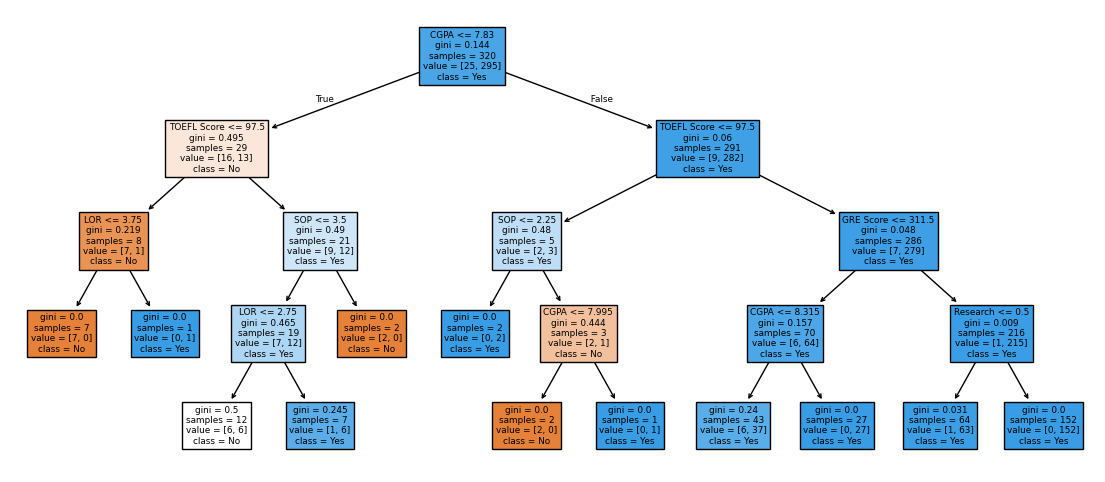

In [9]:
#optional
plt.figure(figsize=(14, 6))
plot_tree(model, feature_names=X.columns, class_names=['No', 'Yes'], filled=True)
plt.show()
